## 13 Individual Route Regularity and Heat Exception (Flag 13)

### Dataset Overview
A constructed WorldTrace case with 216 trajectories. Regular geometries come from observed NYC WorldTrace records; the four heat exceptions start within one kilometer of the regular origin, preserve its destination, and are routed on the OSM road network through Lincoln or Holland Tunnel instead of the regular George Washington Bridge corridor.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze the route regularity in individual mobility among users and find possible abnormal patterns.

Role: Urban mobility analyst


Category: Repeated routes, irregular timing, shared speed pattern, and heat exception

### Your Objective
Use the provided tables and visual results to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; the supporting timestamped trajectory-point table is loaded into `user_df`.

In [ ]:
dataset_path = 'trajectories.csv'
df = pd.read_csv(dataset_path)
df['departure_time'] = pd.to_datetime(df['departure_time'])
df['arrival_time'] = pd.to_datetime(df['arrival_time'])

In [ ]:
user_dataset_path = 'trajectory_points.csv'
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Where do the regular trajectories converge into a shared corridor and later separate toward different destinations, and what share follows this structure?

#### Analysis action

Measure the regular-route share and verify the normalized convergence and separation positions before reading the annotated route map.

regular share 0.9814814814814815
regular source geometries 5
                 trips  convergence  separation     destination
user_id                                                        
regular_user_01     36        0.242       0.691  destination_01
regular_user_02     36        0.214       0.619  destination_02
regular_user_03     36        0.264       0.712  destination_03
regular_user_04     32        0.193       0.644  destination_04
regular_user_05     36        0.220       0.757  destination_05
regular_user_06     36        0.264       0.712  destination_06


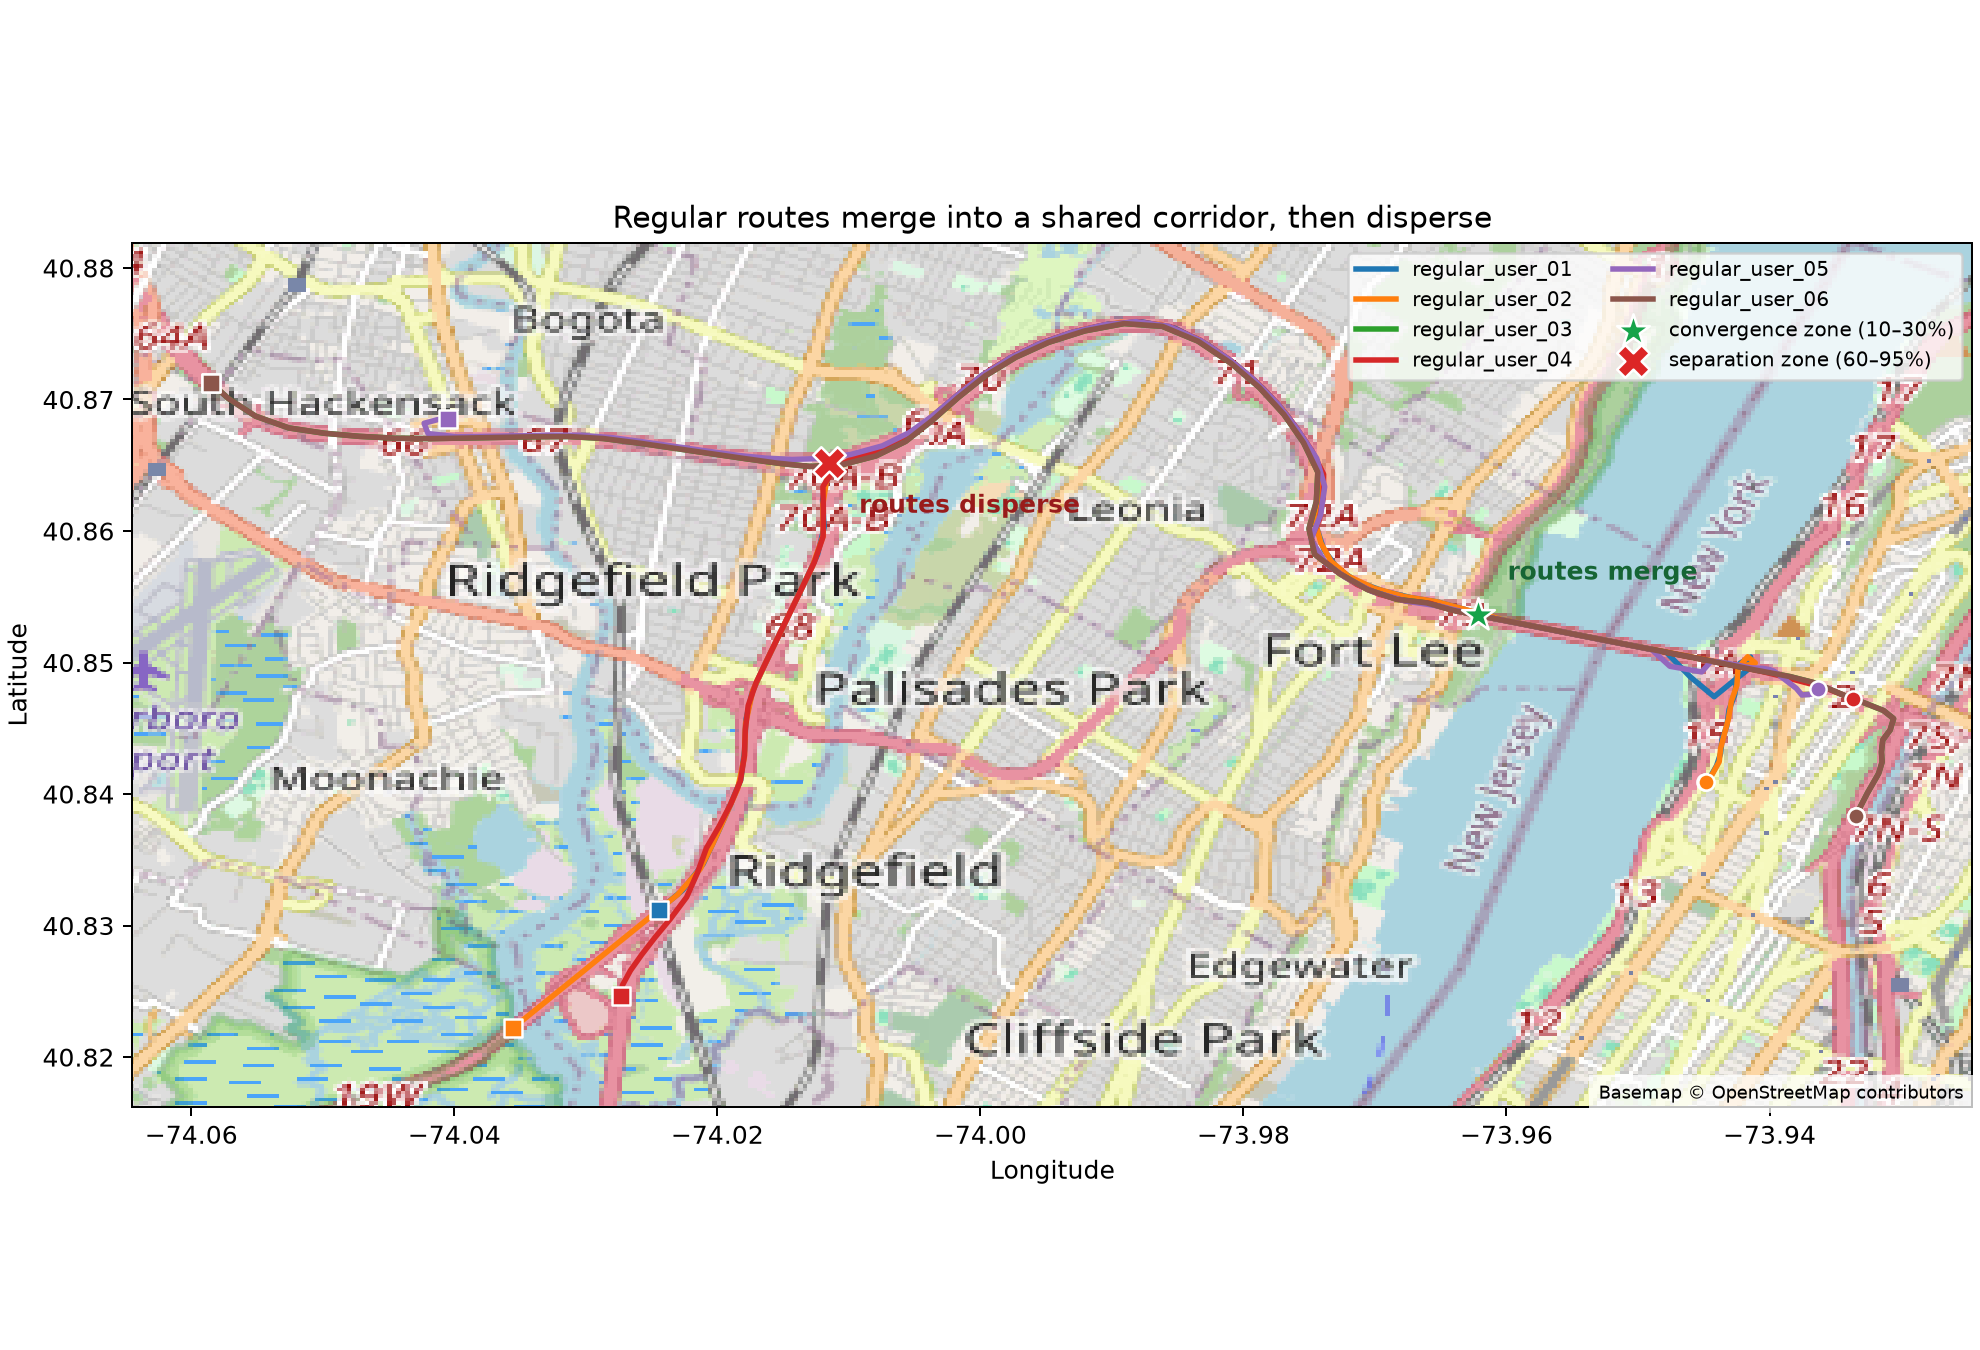

In [1]:
regular=df[df.route_role.eq('regular_corridor')]; print('regular share',len(regular)/len(df)); print('regular source geometries',regular.source_trajectory_id.nunique()); print(regular.groupby('user_id').agg(trips=('trajectory_id','size'),convergence=('convergence_fraction','median'),separation=('separation_fraction','median'),destination=('visited_location','first')))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_1.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex13_insight_1",
  "insight": "These users repeatedly follow a small number of highly similar route geometries across their travel histories.",
  "plot": {
    "plot_type": "annotated_convergence_separation_map",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_1.png"
    ],
    "title": "Individual Route Regularity and Heat Exception: Insight 1",
    "description": "Map-matched regular routes are annotated with their early convergence zone and later separation zone."
  },
  "question": "Where do the regular trajectories converge into a shared corridor and later separate toward different destinations, and what share follows this structure?",
  "actionable_insight": "Measure the regular-route share and verify the normalized convergence and separation positions before reading the annotated route map.",
  "code": "regular=df[df.route_role.eq('regular_corridor')]; print('regular share',len(regular)/len(df)); print('regular source geometries',regular.source_trajectory_id.nunique()); print(regular.groupby('user_id').agg(trips=('trajectory_id','size'),convergence=('convergence_fraction','median'),separation=('separation_fraction','median'),destination=('visited_location','first')))",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "gps_position",
    "trajectory_id",
    "matched_road_position",
    "temperature"
  ]
}

### **Question 2**: Do users leave in a similar daily time window without following a fixed departure time, and do successive trip intervals vary substantially?

#### Analysis action

Plot each user’s departure hour across travel days, then compare the minimum, median, and maximum inter-trip gaps.

Departure-hour summary
                  min  median   std    max
user_id                                   
regular_user_01  6.73    8.19  0.76   9.43
regular_user_02  7.16    8.07  0.69   9.58
regular_user_03  7.07    8.46  0.76   9.76
regular_user_04  7.16    8.70  0.83  10.15
regular_user_05  7.28    8.91  0.87  10.10
regular_user_06  6.93    8.36  0.91   9.81
Inter-trip-gap summary
                   min  median   mean    std     max
user_id                                             
regular_user_01  22.08   25.16  38.36  19.35   72.81
regular_user_02  22.97   25.48  38.43  18.99   72.27
regular_user_03  21.70   47.75  56.22  30.68   97.47
regular_user_04  21.64   25.06  43.14  28.53   97.61
regular_user_05  21.71   47.98  57.62  36.49  121.67
regular_user_06  22.01   47.17  48.04  26.65   98.17


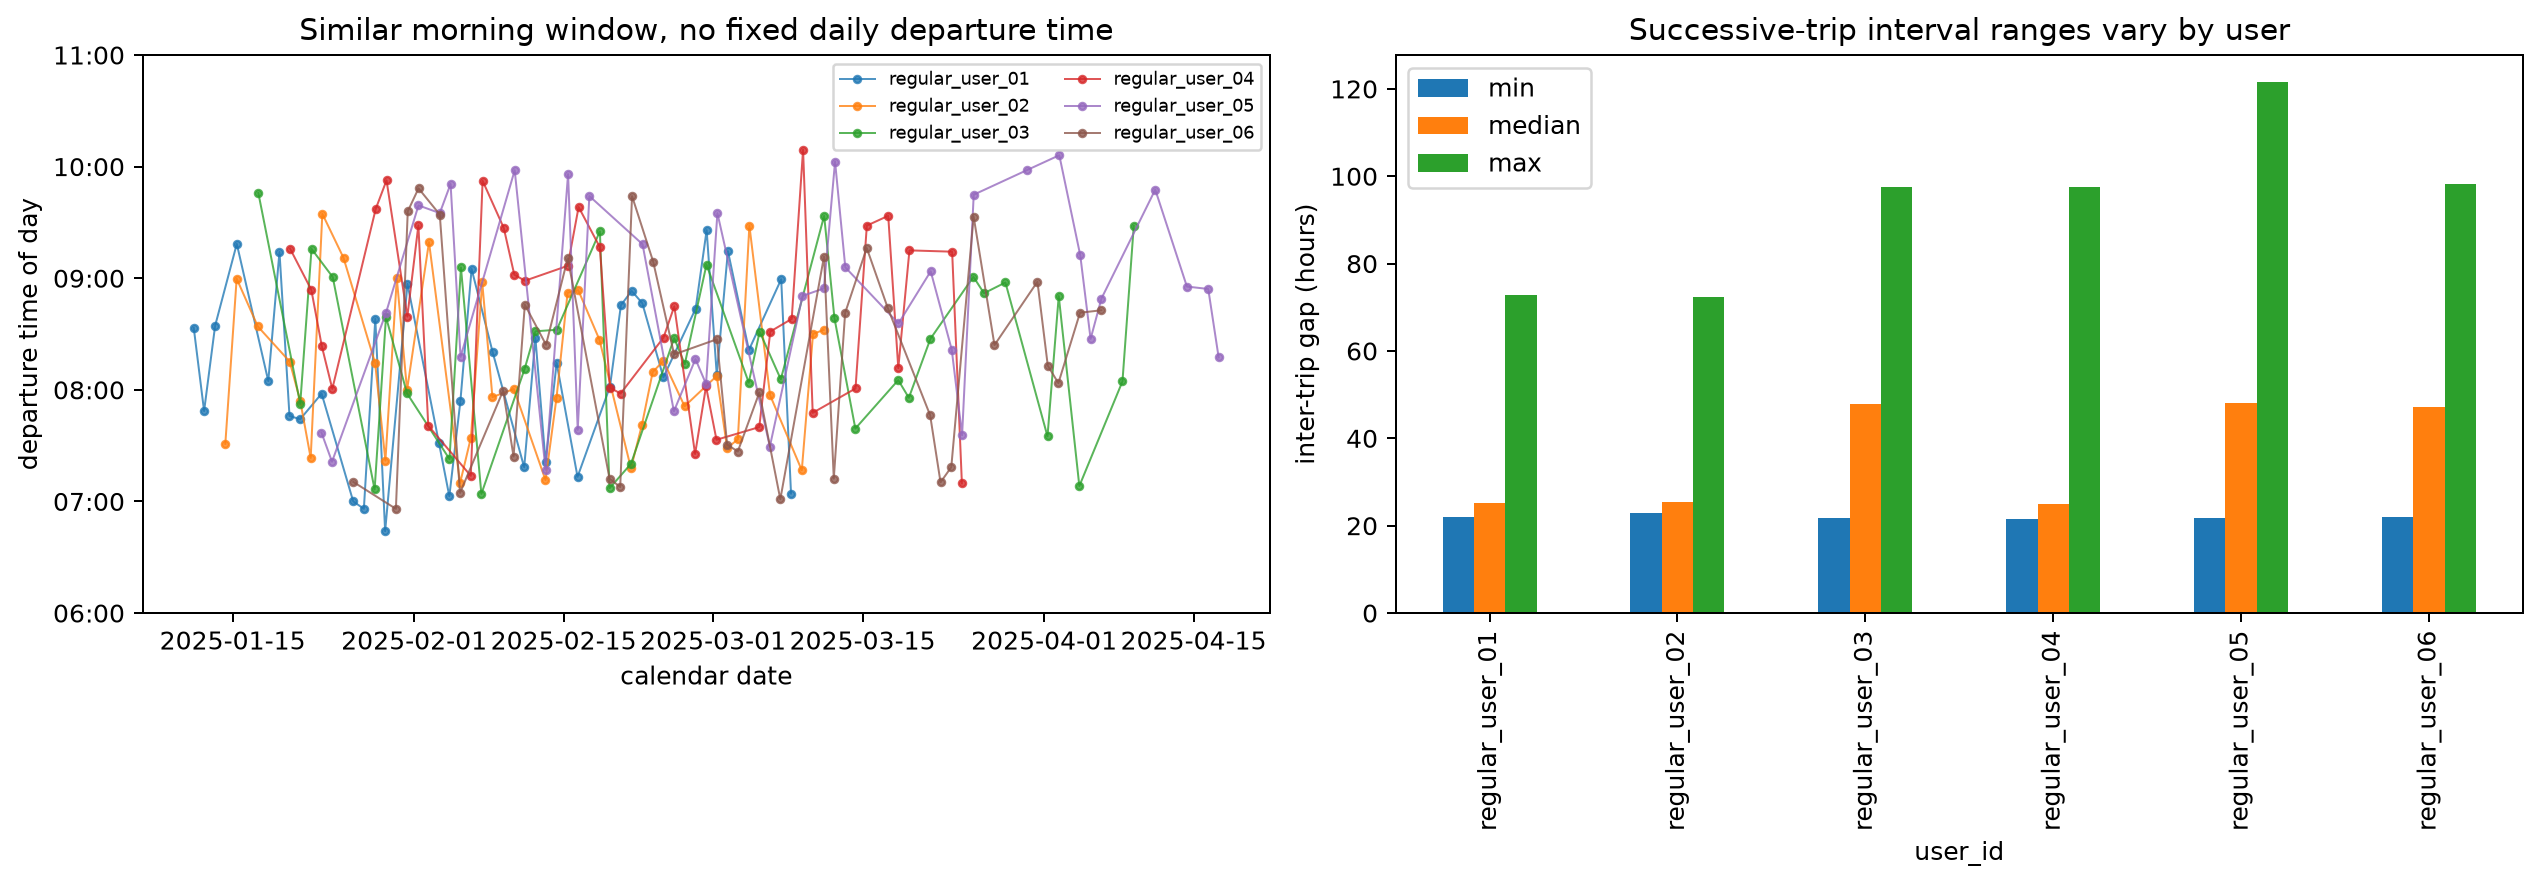

In [2]:
d=df.sort_values(['user_id','departure_time']).copy()
d['departure_hour']=d.departure_time.dt.hour+d.departure_time.dt.minute/60+d.departure_time.dt.second/3600
d['gap_hours']=d.groupby('user_id').departure_time.diff().dt.total_seconds()/3600
hour_summary=d.groupby('user_id').departure_hour.agg(['min','median','std','max'])
gap_summary=d.groupby('user_id').gap_hours.agg(['min','median','mean','std','max'])
print('Departure-hour summary');print(hour_summary.round(2));print('Inter-trip-gap summary');print(gap_summary.round(2))
fig,ax=plt.subplots(1,2,figsize=(14,4.8),constrained_layout=True)
for user,g in d.groupby('user_id'):
    ax[0].plot(g.departure_time,g.departure_hour,marker='o',markersize=2.8,linewidth=.8,alpha=.78,label=user)
ax[0].set(xlabel='calendar date',ylabel='departure time of day',title='Similar morning window, no fixed daily departure time')
ax[0].set_yticks([6,7,8,9,10,11]);ax[0].set_yticklabels([f'{h:02d}:00' for h in [6,7,8,9,10,11]]);ax[0].legend(fontsize=7,ncol=2)
gap_summary[['min','median','max']].plot.bar(ax=ax[1]);ax[1].set(ylabel='inter-trip gap (hours)',title='Successive-trip interval ranges vary by user');plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_2.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex13_insight_2",
  "insight": "These repeated routes are not necessarily associated with regular departure times, and the intervals between successive trips can vary substantially.",
  "plot": {
    "plot_type": "inter_trip_gap_distribution",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_2.png"
    ],
    "title": "Individual Route Regularity and Heat Exception: Insight 2",
    "description": "User-level inter-trip gap distributions show comparable irregularity with non-identical ranges."
  },
  "question": "Do users leave in a similar daily time window without following a fixed departure time, and do successive trip intervals vary substantially?",
  "actionable_insight": "Plot each user’s departure hour across travel days, then compare the minimum, median, and maximum inter-trip gaps.",
  "code": "d=df.sort_values(['user_id','departure_time']).copy()\nd['departure_hour']=d.departure_time.dt.hour+d.departure_time.dt.minute/60+d.departure_time.dt.second/3600\nd['gap_hours']=d.groupby('user_id').departure_time.diff().dt.total_seconds()/3600\nhour_summary=d.groupby('user_id').departure_hour.agg(['min','median','std','max'])\ngap_summary=d.groupby('user_id').gap_hours.agg(['min','median','mean','std','max'])\nprint('Departure-hour summary');print(hour_summary.round(2));print('Inter-trip-gap summary');print(gap_summary.round(2))\nfig,ax=plt.subplots(1,2,figsize=(14,4.8),constrained_layout=True)\nfor user,g in d.groupby('user_id'):\n    ax[0].plot(g.departure_time,g.departure_hour,marker='o',markersize=2.8,linewidth=.8,alpha=.78,label=user)\nax[0].set(xlabel='calendar date',ylabel='departure time of day',title='Similar morning window, no fixed daily departure time')\nax[0].set_yticks([6,7,8,9,10,11]);ax[0].set_yticklabels([f'{h:02d}:00' for h in [6,7,8,9,10,11]]);ax[0].legend(fontsize=7,ncol=2)\ngap_summary[['min','median','max']].plot.bar(ax=ax[1]);ax[1].set(ylabel='inter-trip gap (hours)',title='Successive-trip interval ranges vary by user');plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trajectory_timestamp",
    "trajectory_id",
    "matched_road_position",
    "temperature"
  ]
}

### **Question 3**: How similar are the users’ complete driving-speed patterns along the shared corridor, including location-wise profiles, means, variation, and ranges?

#### Analysis action

Normalize point positions along each regular trip and compare user-level speed profiles together with mean speed, within-trip variance, and observed ranges.

                      mean       std    min    max
user_id                                           
regular_user_01  33.804996  4.623120  23.75  42.75
regular_user_02  34.890780  4.963734  24.50  44.09
regular_user_03  33.062063  4.359224  23.83  41.65
regular_user_04  35.786871  5.309890  25.03  45.14
regular_user_05  34.591087  4.847021  24.56  43.60
regular_user_06  35.473186  5.164462  25.08  44.81
mean centered-profile correlation 0.9857247629542808


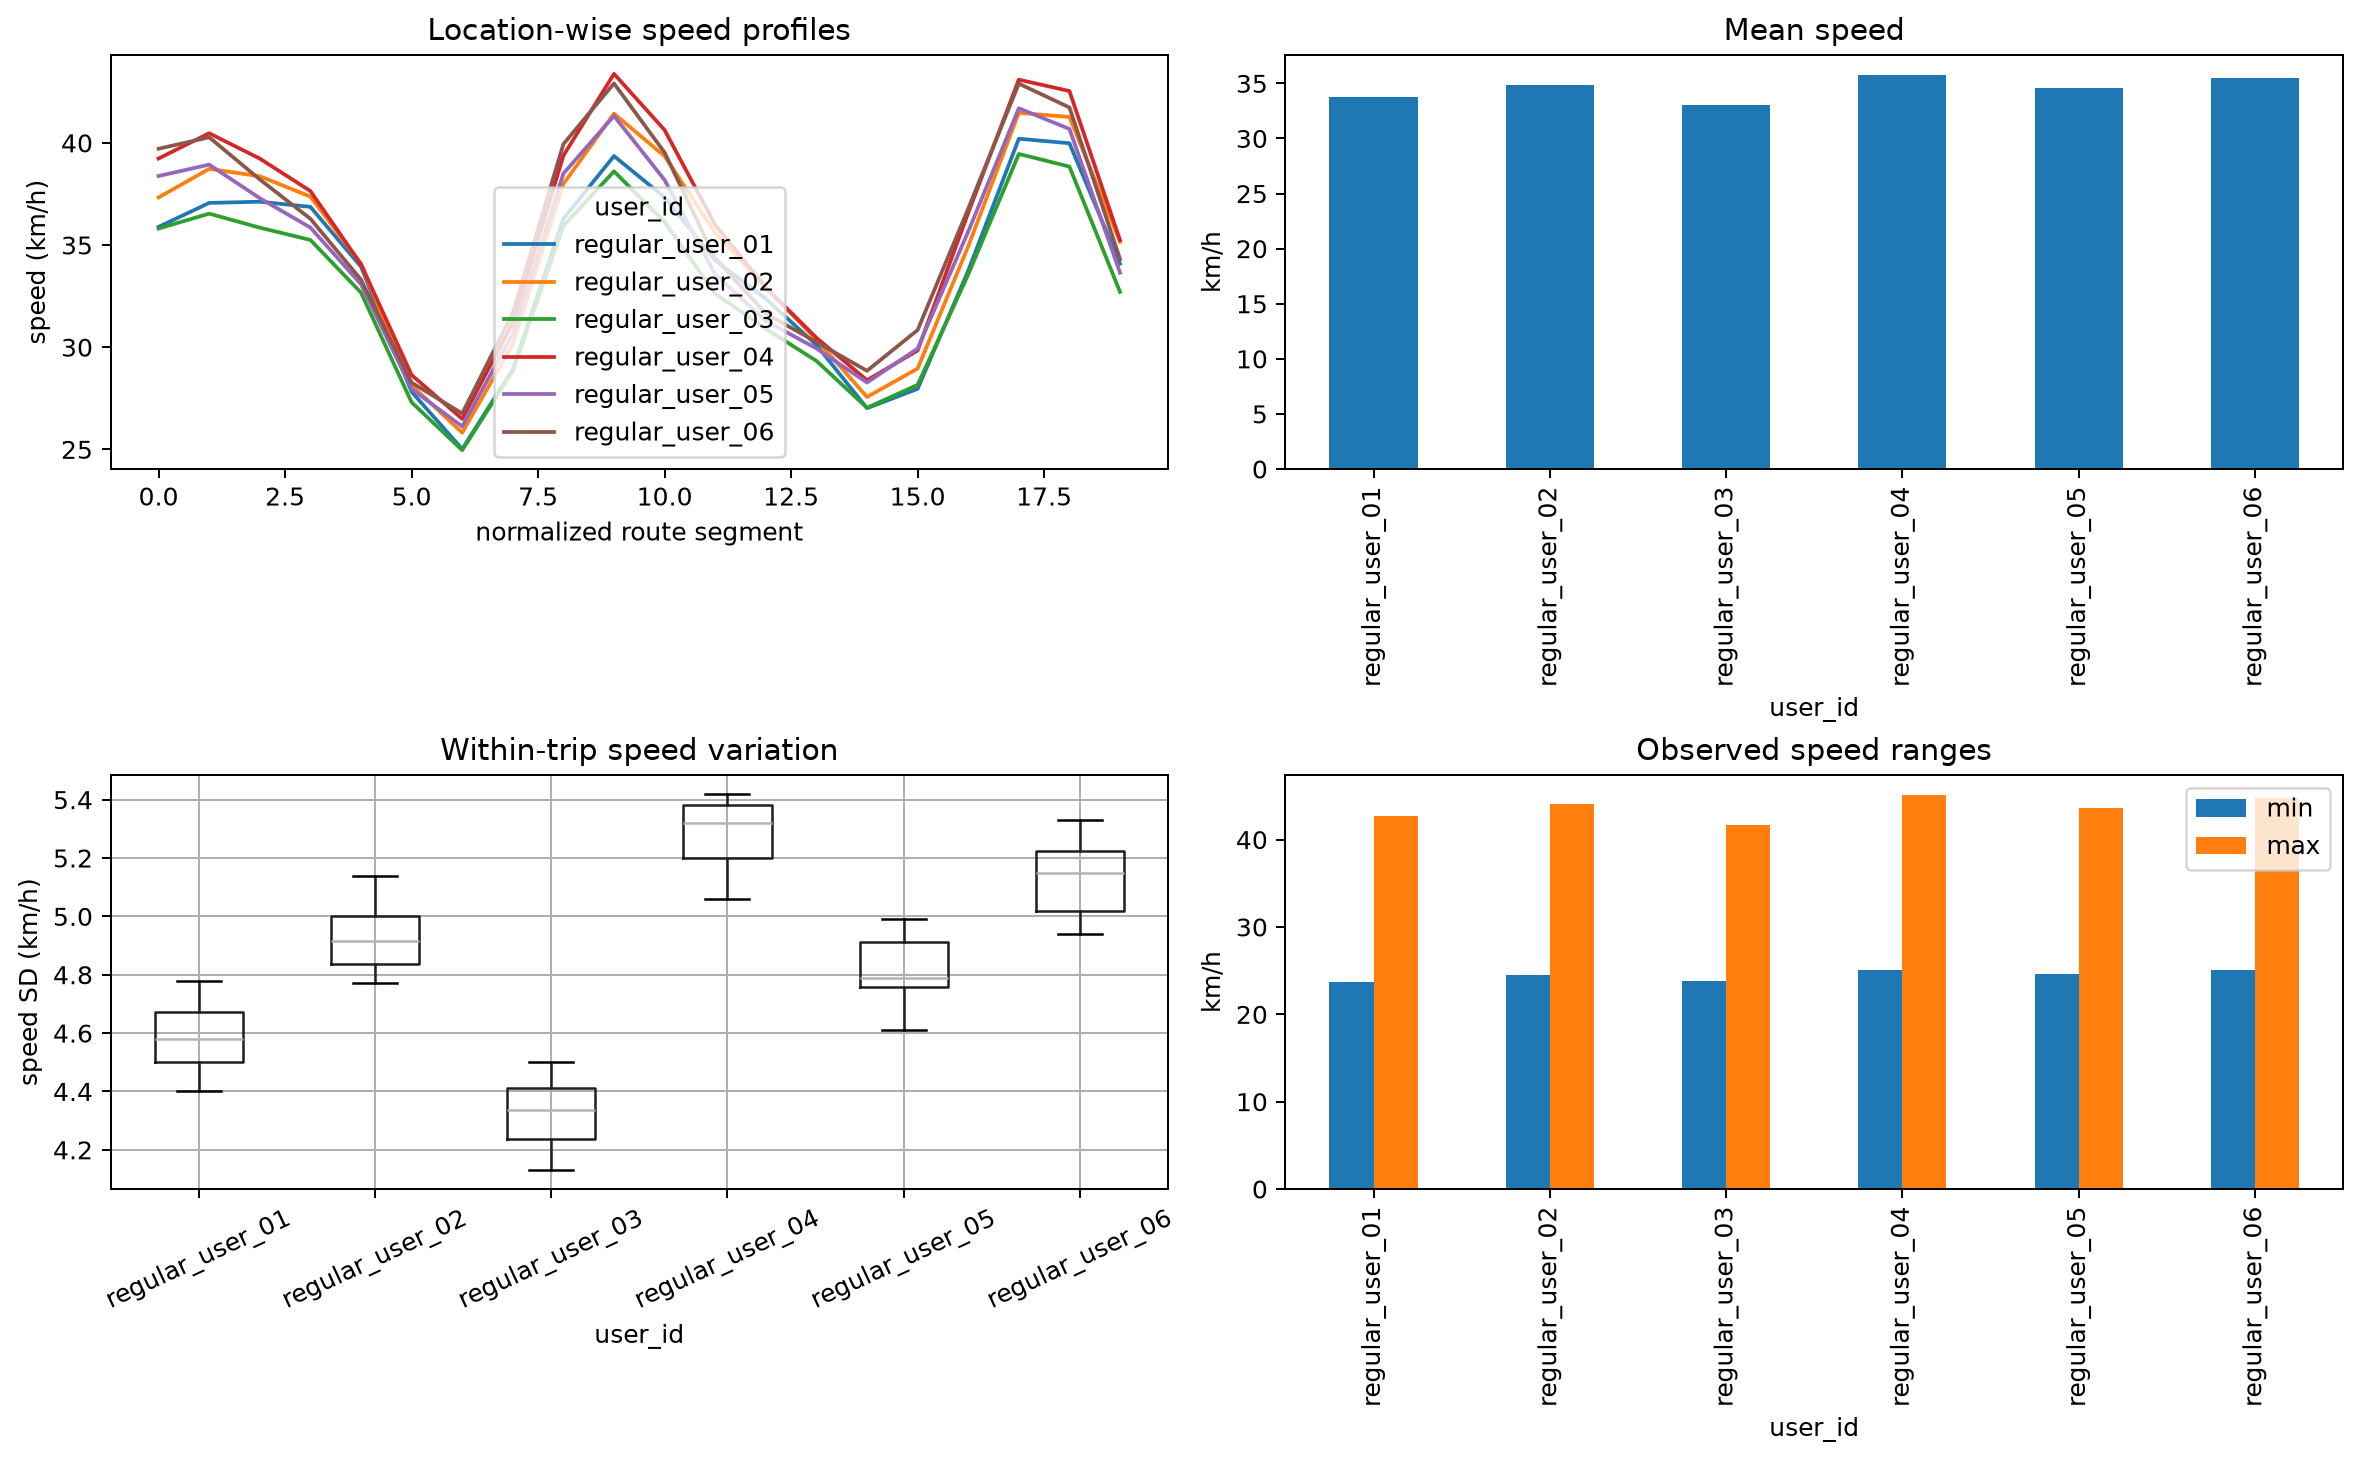

In [3]:
regular=df[df.route_role.eq('regular_corridor')][['trajectory_id','user_id','point_count','mean_speed_kmh','within_trip_speed_sd_kmh']]
q=user_df.merge(regular[['trajectory_id','user_id','point_count']],on=['trajectory_id','user_id'])
q['progress']=q.point_index/(q.point_count-1);q['segment']=np.minimum((q.progress*20).astype(int),19)
profile=q.groupby(['user_id','segment']).speed_kmh.mean().unstack(0)
stats=q.groupby('user_id').speed_kmh.agg(['mean','std','min','max']);print(stats);print('mean centered-profile correlation',profile.corr().where(~np.eye(len(profile.columns),dtype=bool)).stack().mean())
fig,ax=plt.subplots(2,2,figsize=(13,8),constrained_layout=True)
profile.plot(ax=ax[0,0]);ax[0,0].set(xlabel='normalized route segment',ylabel='speed (km/h)',title='Location-wise speed profiles')
stats['mean'].plot.bar(ax=ax[0,1]);ax[0,1].set(ylabel='km/h',title='Mean speed')
regular.boxplot(column='within_trip_speed_sd_kmh',by='user_id',ax=ax[1,0],rot=25);ax[1,0].set(title='Within-trip speed variation',ylabel='speed SD (km/h)')
stats[['min','max']].plot.bar(ax=ax[1,1]);ax[1,1].set(ylabel='km/h',title='Observed speed ranges');plt.suptitle('');plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_3.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex13_insight_3",
  "insight": "The driving speed patterns of different users on this highly similar route are similar.",
  "plot": {
    "plot_type": "multi_metric_speed_profile",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_3.png"
    ],
    "title": "Individual Route Regularity and Heat Exception: Insight 3",
    "description": "Normalized location-wise speed profiles are shown together with mean, variance, and range summaries."
  },
  "question": "How similar are the users’ complete driving-speed patterns along the shared corridor, including location-wise profiles, means, variation, and ranges?",
  "actionable_insight": "Normalize point positions along each regular trip and compare user-level speed profiles together with mean speed, within-trip variance, and observed ranges.",
  "code": "regular=df[df.route_role.eq('regular_corridor')][['trajectory_id','user_id','point_count','mean_speed_kmh','within_trip_speed_sd_kmh']]\nq=user_df.merge(regular[['trajectory_id','user_id','point_count']],on=['trajectory_id','user_id'])\nq['progress']=q.point_index/(q.point_count-1);q['segment']=np.minimum((q.progress*20).astype(int),19)\nprofile=q.groupby(['user_id','segment']).speed_kmh.mean().unstack(0)\nstats=q.groupby('user_id').speed_kmh.agg(['mean','std','min','max']);print(stats);print('mean centered-profile correlation',profile.corr().where(~np.eye(len(profile.columns),dtype=bool)).stack().mean())\nfig,ax=plt.subplots(2,2,figsize=(13,8),constrained_layout=True)\nprofile.plot(ax=ax[0,0]);ax[0,0].set(xlabel='normalized route segment',ylabel='speed (km/h)',title='Location-wise speed profiles')\nstats['mean'].plot.bar(ax=ax[0,1]);ax[0,1].set(ylabel='km/h',title='Mean speed')\nregular.boxplot(column='within_trip_speed_sd_kmh',by='user_id',ax=ax[1,0],rot=25);ax[1,0].set(title='Within-trip speed variation',ylabel='speed SD (km/h)')\nstats[['min','max']].plot.bar(ax=ax[1,1]);ax[1,1].set(ylabel='km/h',title='Observed speed ranges');plt.suptitle('');plt.show()",
  "insight_type": "overall_pattern",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id",
    "matched_road_position",
    "temperature"
  ]
}

### **Question 4**: Is route changing above 30°C an isolated behavior belonging to one user, and what clearly different comparable-OD crossing routes does that user take?

#### Analysis action

Identify every above-30°C record, verify that only one user is involved, confirm a sub-kilometer origin difference and the same destination, and compare Lincoln/Holland Tunnel alternatives with the normal George Washington Bridge corridor.

 trip_index         user_id  temperature_c        route_role source_trajectory_id             crossing_context visited_location  start_latitude  start_longitude  end_latitude  end_longitude  trajectory_distance_km  origin_error_km  destination_error_km
         63 regular_user_04           31.8 heat_route_change    osrm_lincoln_west Lincoln_Tunnel_west_approach   destination_04       40.843942       -73.942703     40.824666      -74.02736                  29.494         0.852267              0.000597
        107 regular_user_04           32.6 heat_route_change    osrm_lincoln_east Lincoln_Tunnel_east_approach   destination_04       40.843942       -73.942703     40.824666      -74.02736                  32.646         0.852267              0.000597
        160 regular_user_04           33.4 heat_route_change    osrm_holland_west Holland_Tunnel_west_approach   destination_04       40.843942       -73.942703     40.824666      -74.02736                  38.697         0.852267           

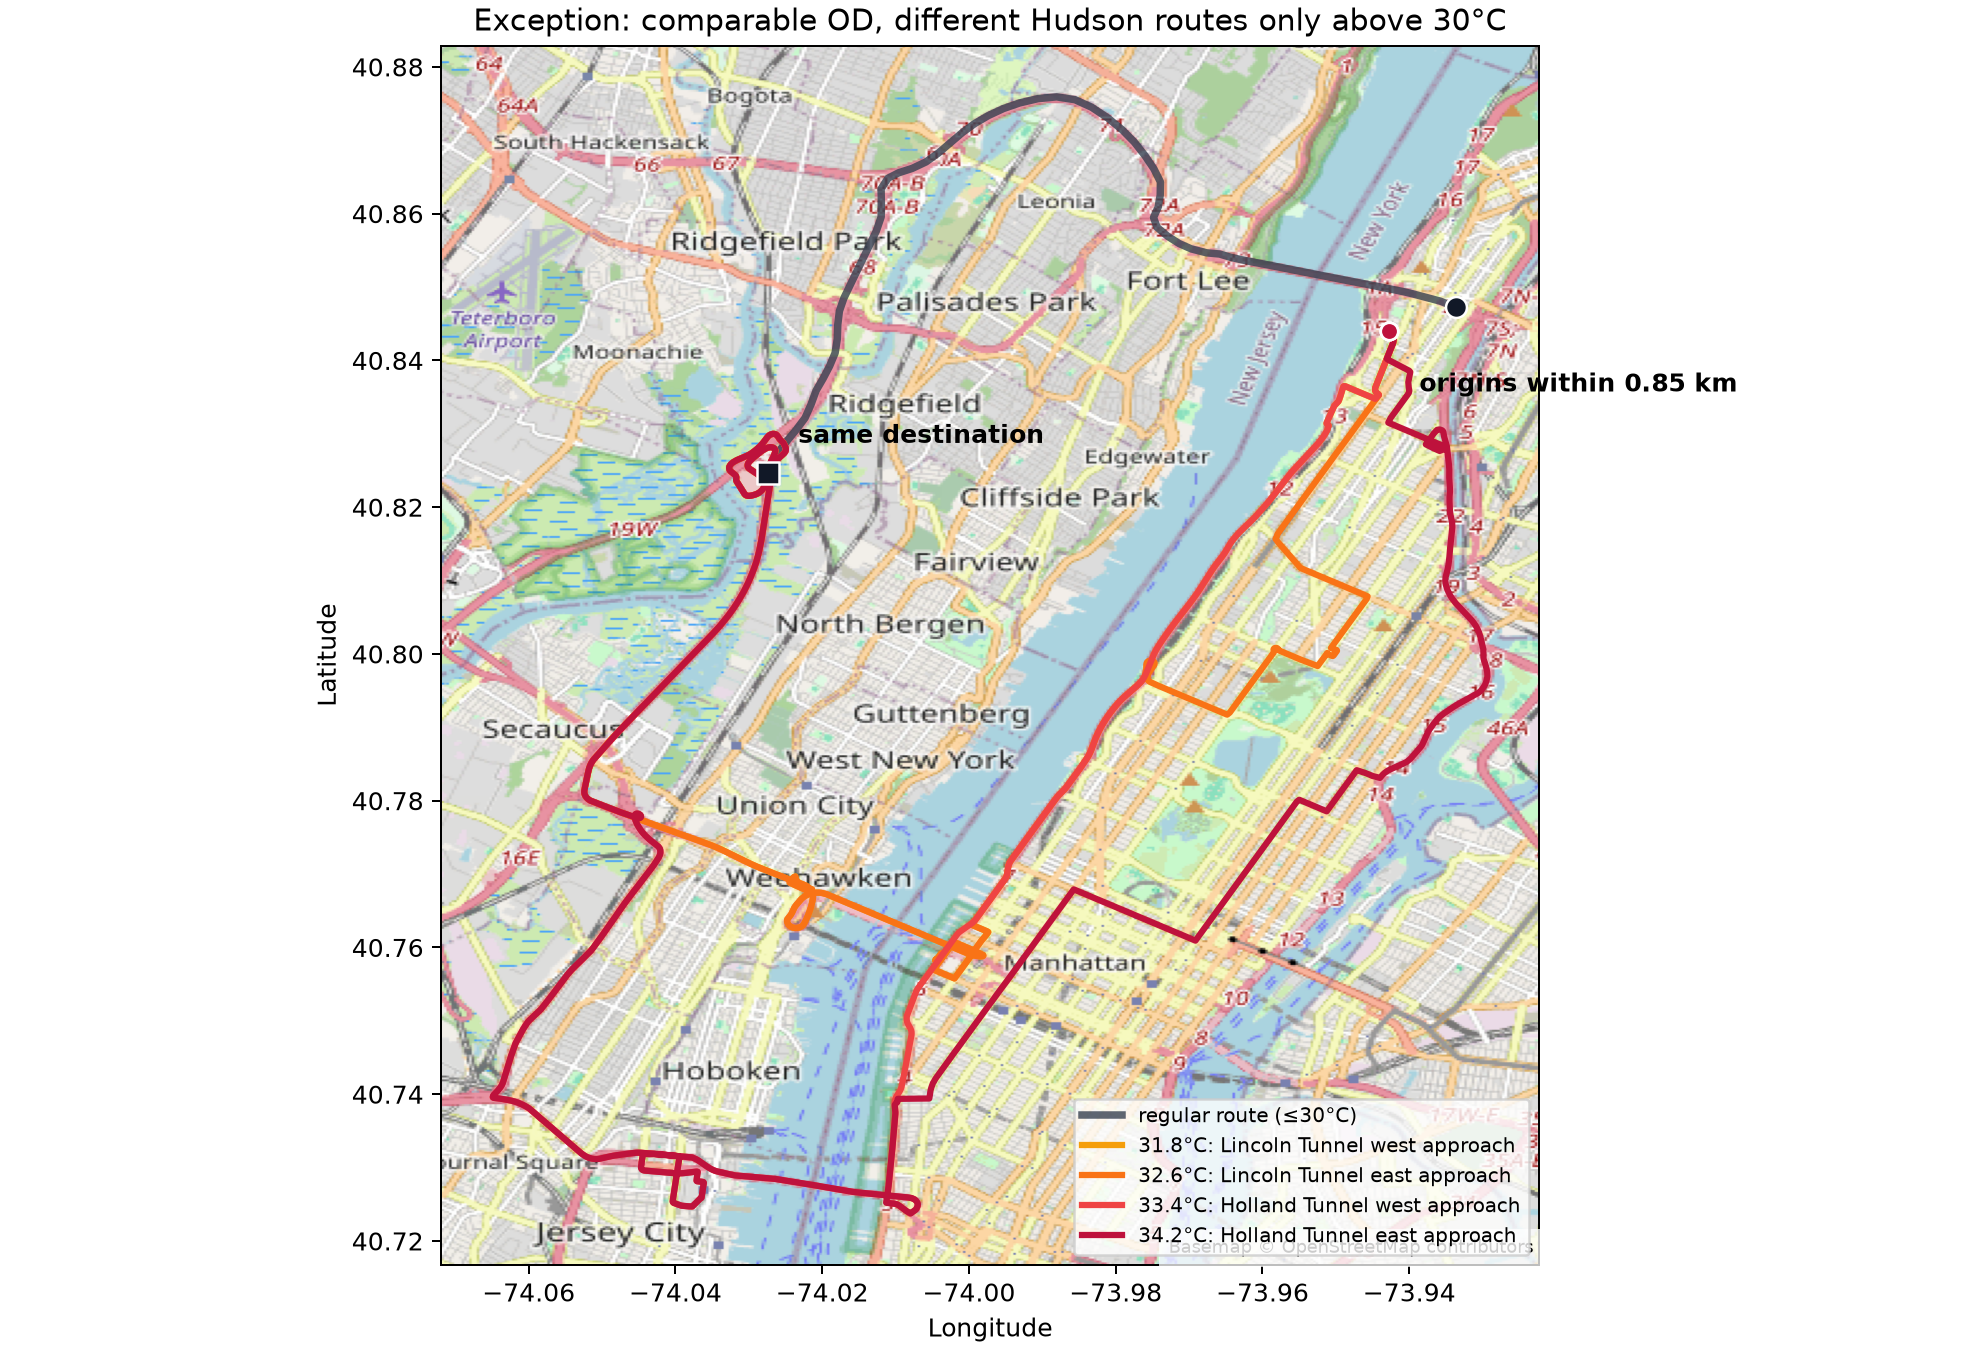

In [4]:
cols=['trip_index','user_id','temperature_c','route_role','source_trajectory_id','crossing_context','visited_location','start_latitude','start_longitude','end_latitude','end_longitude','trajectory_distance_km']
hot=df[df.temperature_c.gt(30)][cols].sort_values('temperature_c').copy()
normal=df[df.user_id.eq('regular_user_04')&df.route_role.eq('regular_corridor')].iloc[0]
hot['origin_error_km']=np.sqrt(((hot.start_latitude-normal.start_latitude)*111)**2+((hot.start_longitude-normal.start_longitude)*85)**2)
hot['destination_error_km']=np.sqrt(((hot.end_latitude-normal.end_latitude)*111)**2+((hot.end_longitude-normal.end_longitude)*85)**2)
print(hot.to_string(index=False));print('regular distance km',normal.trajectory_distance_km);print('affected users',hot.user_id.unique().tolist());print('distinct hot routes',hot.source_trajectory_id.nunique());print('other users above 30°C',df[df.temperature_c.gt(30)&~df.user_id.eq('regular_user_04')].shape[0])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/insight_4.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "worldtrace_ex13_insight_4",
  "insight": "A user change his routes during temperature over 30 degrees.",
  "plot": {
    "plot_type": "temperature_conditioned_route_exception_map",
    "files": [
      "visualizations/trajectory_map.png",
      "visualizations/insight_4.png"
    ],
    "title": "Individual Route Regularity and Heat Exception: Insight 4",
    "description": "The sole affected user’s normal route and four above-30°C alternatives with a nearby origin and identical destination are overlaid on an OSM basemap."
  },
  "question": "Is route changing above 30°C an isolated behavior belonging to one user, and what clearly different comparable-OD crossing routes does that user take?",
  "actionable_insight": "Identify every above-30°C record, verify that only one user is involved, confirm a sub-kilometer origin difference and the same destination, and compare Lincoln/Holland Tunnel alternatives with the normal George Washington Bridge corridor.",
  "code": "cols=['trip_index','user_id','temperature_c','route_role','source_trajectory_id','crossing_context','visited_location','start_latitude','start_longitude','end_latitude','end_longitude','trajectory_distance_km']\nhot=df[df.temperature_c.gt(30)][cols].sort_values('temperature_c').copy()\nnormal=df[df.user_id.eq('regular_user_04')&df.route_role.eq('regular_corridor')].iloc[0]\nhot['origin_error_km']=np.sqrt(((hot.start_latitude-normal.start_latitude)*111)**2+((hot.start_longitude-normal.start_longitude)*85)**2)\nhot['destination_error_km']=np.sqrt(((hot.end_latitude-normal.end_latitude)*111)**2+((hot.end_longitude-normal.end_longitude)*85)**2)\nprint(hot.to_string(index=False));print('regular distance km',normal.trajectory_distance_km);print('affected users',hot.user_id.unique().tolist());print('distinct hot routes',hot.source_trajectory_id.nunique());print('other users above 30°C',df[df.temperature_c.gt(30)&~df.user_id.eq('regular_user_04')].shape[0])",
  "insight_type": "exception_deviation",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "gps_position",
    "temperature",
    "trajectory_id",
    "matched_road_position"
  ]
}

### Summary of Findings (Flag 13)

These users repeatedly follow a small number of highly similar route geometries across their travel histories. These repeated routes are not necessarily associated with regular departure times, and the intervals between successive trips can vary substantially. The driving speed patterns of different users on this highly similar route are similar. A user change his routes during temperature over 30 degrees.